In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

In [79]:
train_set = pd.read_csv("train.csv")
test_set = pd.read_csv("test.csv")

X = train_set.drop(columns=['Exited'])
y = train_set['Exited']

print(f"Train shape : {train_set.shape}")
print(f"Test shape  : {test_set.shape}")

Train shape : (15000, 14)
Test shape  : (10000, 13)


In [80]:
train_set.head(10)

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15617304.0,Macdonald,675.0,France,Female,37.0,5.0,0.00,1.0,1.0,0.0,131778.57,1.0
1,1,15575409.0,Chien,599.0,France,Male,28.0,8.0,0.00,1.0,1.0,0.0,81299.09,0.0
2,2,15730688.0,Ritchie,706.0,Germany,Female,40.0,9.0,155619.58,1.0,1.0,1.0,81622.08,1.0
3,3,15758831.0,Chukwufumnanya,705.0,Germany,Male,42.0,3.0,81231.85,2.0,1.0,0.0,134720.51,0.0
4,4,15793331.0,Ch'ien,597.0,France,Male,49.0,9.0,0.00,1.0,1.0,0.0,151844.81,1.0
5,5,15757867.0,Omeokachie,775.0,Germany,Female,37.0,8.0,114370.41,1.0,1.0,1.0,102908.91,0.0
6,6,15597909.0,Nwachukwu,576.0,France,Female,43.0,9.0,0.00,1.0,1.0,1.0,144532.85,0.0
7,7,15614643.0,Ngozichukwuka,703.0,France,Male,24.0,6.0,0.00,2.0,1.0,0.0,93829.79,0.0
8,8,15572294.0,Ts'ai,549.0,Germany,Female,30.0,8.0,102025.32,2.0,1.0,1.0,175722.31,0.0
9,9,15703614.0,Onyemere,579.0,Spain,Male,35.0,2.0,0.00,1.0,1.0,1.0,170886.59,0.0


In [81]:
train_set.describe()

,id,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,15000.000000,1.500000e+04,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,1.500000e+04,15000.000000
mean,7499.500000,1.569254e+07,658.549933,37.688333,5.039733,43365.350921,1.584733,0.780533,0.493000,1.197492e+05,0.203533
std,4330.271354,7.221883e+04,73.315114,8.132487,2.809558,59914.926512,0.527041,0.413899,0.499968,1.618335e+05,0.402639
min,0.000000,1.556490e+07,431.000000,18.000000,0.000000,0.000000,1.000000,0.000000,0.000000,4.795400e+02,0.000000
25%,3749.750000,1.563247e+07,602.000000,32.000000,3.000000,0.000000,1.000000,1.000000,0.000000,8.347296e+04,0.000000
50%,7499.500000,1.569139e+07,661.000000,37.000000,5.000000,0.000000,2.000000,1.000000,0.000000,1.240456e+05,0.000000
75%,11249.250000,1.575805e+07,710.000000,42.000000,7.000000,109949.125000,2.000000,1.000000,1.000000,1.570971e+05,0.000000
max,14999.000000,1.581569e+07,850.000000,74.000000,30.000000,187841.990000,4.000000,1.000000,1.000000,1.817172e+07,1.000000


In [82]:
train_set.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               15000 non-null  int64  
 1   CustomerId       15000 non-null  float64
 2   Surname          15000 non-null  str    
 3   CreditScore      15000 non-null  float64
 4   Geography        15000 non-null  str    
 5   Gender           15000 non-null  str    
 6   Age              15000 non-null  float64
 7   Tenure           15000 non-null  float64
 8   Balance          15000 non-null  float64
 9   NumOfProducts    15000 non-null  float64
 10  HasCrCard        15000 non-null  float64
 11  IsActiveMember   15000 non-null  float64
 12  EstimatedSalary  15000 non-null  float64
 13  Exited           15000 non-null  float64
dtypes: float64(10), int64(1), str(3)
memory usage: 1.6 MB


In [83]:
train_set.duplicated().sum()

np.int64(0)

In [84]:
train_set.isnull().sum()

id                 0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [85]:
train_set.describe()

,id,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,15000.000000,1.500000e+04,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,1.500000e+04,15000.000000
mean,7499.500000,1.569254e+07,658.549933,37.688333,5.039733,43365.350921,1.584733,0.780533,0.493000,1.197492e+05,0.203533
std,4330.271354,7.221883e+04,73.315114,8.132487,2.809558,59914.926512,0.527041,0.413899,0.499968,1.618335e+05,0.402639
min,0.000000,1.556490e+07,431.000000,18.000000,0.000000,0.000000,1.000000,0.000000,0.000000,4.795400e+02,0.000000
25%,3749.750000,1.563247e+07,602.000000,32.000000,3.000000,0.000000,1.000000,1.000000,0.000000,8.347296e+04,0.000000
50%,7499.500000,1.569139e+07,661.000000,37.000000,5.000000,0.000000,2.000000,1.000000,0.000000,1.240456e+05,0.000000
75%,11249.250000,1.575805e+07,710.000000,42.000000,7.000000,109949.125000,2.000000,1.000000,1.000000,1.570971e+05,0.000000
max,14999.000000,1.581569e+07,850.000000,74.000000,30.000000,187841.990000,4.000000,1.000000,1.000000,1.817172e+07,1.000000


In [86]:
test_id = test_set['id'].copy()
train_set = train_set.drop(columns=['id', 'CustomerId', 'Surname'])
test_set = test_set.drop(columns=['id','CustomerId','Surname'])

In [87]:
train_set.columns

Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
       'Exited'],
      dtype='str')

In [88]:
set(train_set.columns) - set(test_set.columns)

{'Exited'}

In [89]:
train_set.groupby('Exited')[['Age', 'CreditScore', 'Balance', 'EstimatedSalary', 'Tenure']].mean()

,Age,CreditScore,Balance,EstimatedSalary,Tenure
Exited,,,,,
0.0,35.829413,660.297397,39072.890201,119060.888270,5.077676
1.0,44.962660,651.711759,60162.608772,122442.825319,4.891255


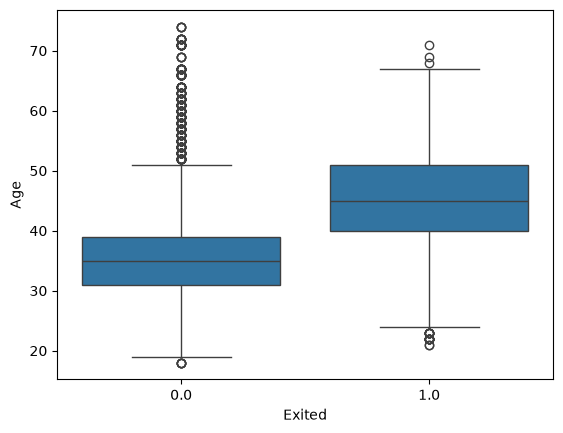

In [90]:
sns.boxplot(x='Exited', y='Age', data=train_set)
plt.show()

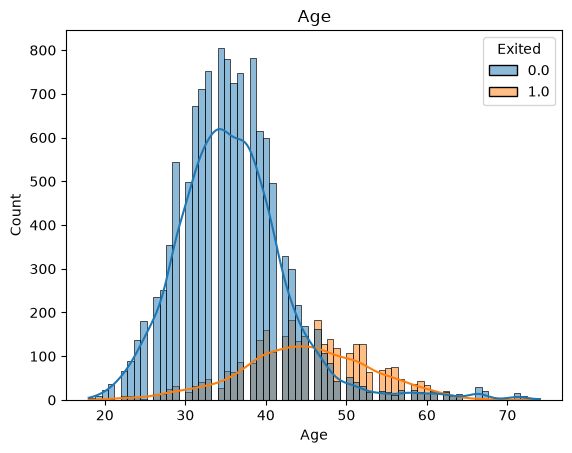

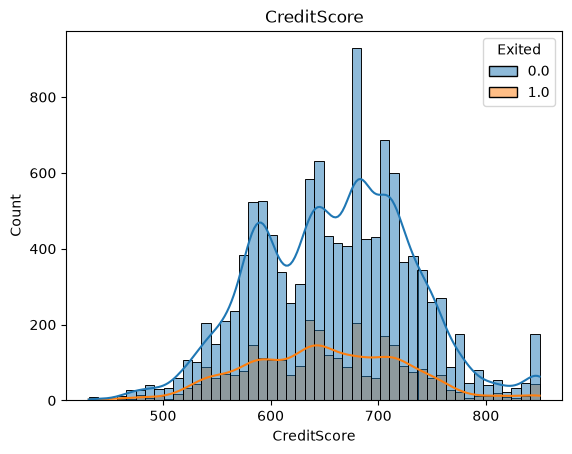

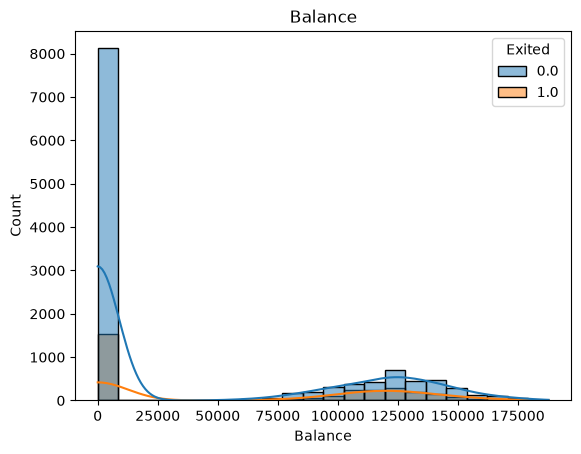

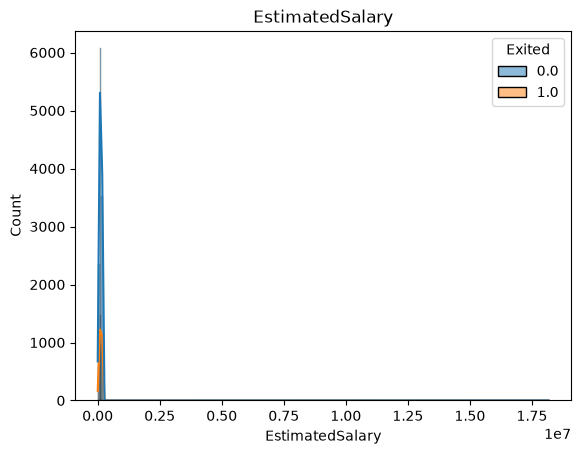

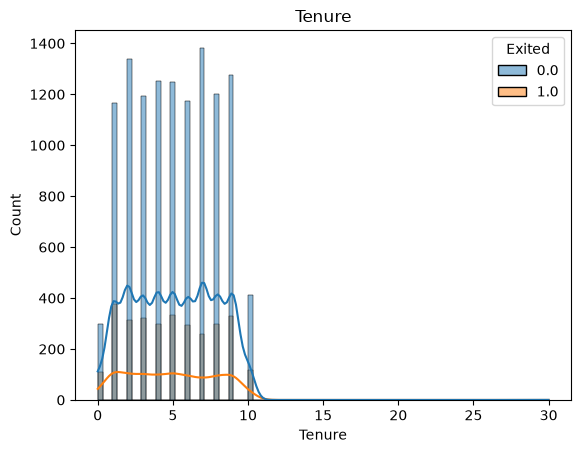

In [102]:
num_cols = ['Age', 'CreditScore', 'Balance', 'EstimatedSalary', 'Tenure']

for col in num_cols:
    sns.histplot(data=train_set, x=col, hue='Exited', kde=True)
    plt.title(col)
    plt.show()

In [104]:
train_set['EstimatedSalary'].describe()

count    1.500000e+04
mean     1.197492e+05
std      1.618335e+05
min      4.795400e+02
25%      8.347296e+04
50%      1.240456e+05
75%      1.570971e+05
max      1.817172e+07
Name: EstimatedSalary, dtype: float64

In [116]:
train_set['EstimatedSalary'].sort_values(ascending=False).head(10)
#(train_set['EstimatedSalary'] > 5000000).sum()

13795    18171718.73
7723      6090941.27
62         199992.48
6604       199992.48
8233       199953.33
12721      199953.33
6922       199808.10
14423      199808.10
9979       199761.29
570        199761.29
Name: EstimatedSalary, dtype: float64

In [117]:
train_set['EstimatedSalary'] = train_set['EstimatedSalary'].clip(upper=200000)

In [119]:
train_set['EstimatedSalary'].describe()

count     15000.000000
mean     118158.381191
std       45660.394470
min         479.540000
25%       83472.965000
50%      124045.650000
75%      157097.090000
max      200000.000000
Name: EstimatedSalary, dtype: float64

In [120]:
test_set['EstimatedSalary'].max()

np.float64(199953.33)

In [94]:
for col in ["Geography", 'Gender', 'IsActiveMember', 'NumOfProducts', 'HasCrCard']:
    print(train_set.groupby(col)['Exited'].mean())
    print()

Geography
France     0.155188
Germany    0.400657
Spain      0.171768
Name: Exited, dtype: float64

Gender
Female    0.280897
Male      0.142037
Name: Exited, dtype: float64

IsActiveMember
0.0    0.284550
1.0    0.120216
Name: Exited, dtype: float64

NumOfProducts
1.0    0.382821
2.0    0.043489
3.0    0.942308
4.0    1.000000
Name: Exited, dtype: float64

HasCrCard
0.0    0.206561
1.0    0.202682
Name: Exited, dtype: float64



In [97]:
train_set['NumOfProducts'].value_counts()

NumOfProducts
2.0    8301
1.0    6473
3.0     208
4.0      18
Name: count, dtype: int64

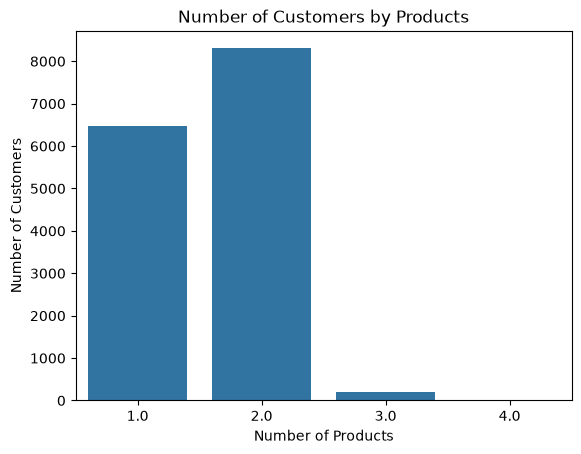

In [98]:
sns.countplot(data=train_set, x='NumOfProducts')

plt.title('Number of Customers by Products')
plt.xlabel('Number of Products')
plt.ylabel('Number of Customers')
plt.show()